# Fine-tuning our NN with controlled comparisons

This applies Yifei's comparison approach to **our MLP**. His files are not
changed or imported. Run from `24_10_2026_TianFeng`; the relative paths read
the existing shared training data. This notebook never reads test data.

First compare 19 configurations on the same three participant folds.
Then repeat the reference, the four strongest offline candidates and the
strongest past-only candidate with two more split/training seed schedules:
**93 model fits in total**. Plain NN and NN + posture memory are both scored.
The printed results are calculated by the code, not entered as score tables.

The selected main model is in `nn_model.ipynb`. Run that file for normal
training and evaluation; this file repeats the longer comparison study.


## 1. Imports and comparison settings

Keep the hidden layers, optimiser, batch size and dropout fixed while
comparing preprocessing and class balancing. The original reference stops
on all-class macro-F1 to reproduce the old procedure. Other trials stop
on the project's six-transition macro-F1, with patience 12 and at most 100 epochs.
`ALLOW_NEXT_WINDOW` determines whether the final selection may use offline context.


In [1]:
import os
from copy import deepcopy
from pathlib import Path

for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ.setdefault(name, '2')

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(2)
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
BATCH_SIZE = 128
MAX_EPOCHS = 100
PATIENCE = 12
ALLOW_NEXT_WINDOW = True


## 2. Read training data only

Use the existing CSV's 561 feature columns, excluding its participant and
activity metadata. Labels and participant IDs use the matching shared text
files. Participant ID controls validation splits and context boundaries;
it is never a predictor. The test split stays out of selection.


In [2]:
data = Path('../smartphone+based+recognition+of+human+activities+and+postural+transitions')
X = np.loadtxt('../Minh/hapt_train.csv', delimiter=',', skiprows=1,
               usecols=range(3, 564), dtype=np.float32)
y = np.loadtxt(data / 'Train/y_train.txt', dtype=int) - 1
subject = np.loadtxt(data / 'Train/subject_id_train.txt', dtype=int)
names = np.loadtxt(data / 'activity_labels.txt', dtype=str)[:, 1].tolist()
print('Training data:', X.shape, '| Participants:', len(np.unique(subject)))


Training data: (7767, 561) | Participants: 21


## 3. Build the four input representations

Offsets describe the neighbouring rows: `-1` is the previous window,
`0` is current and `1` is following. Missing neighbours at participant
boundaries are replaced by the current window. We build context before
sampling or shuffling, so neighbouring rows remain the original neighbours.

Whole participants belong to a single fold, so a validation context cannot
contain training-participant features. Temporal order and within-person
recording boundaries remain assumptions of the supplied window files.


In [3]:
views = {}
rows = np.arange(len(X))
for name, offsets in [('single', [0]), ('past2', [-1, 0]),
                      ('past3', [-2, -1, 0]), ('offline3', [-1, 0, 1])]:
    blocks = []
    for offset in offsets:
        neighbor = np.clip(rows + offset, 0, len(X) - 1)
        boundary = subject[neighbor] != subject
        neighbor[boundary] = rows[boundary]
        blocks.append(X[neighbor])
    views[name] = np.hstack(blocks)
print('Input dimensions:', {name: values.shape[1] for name, values in views.items()})


Input dimensions: {'single': 561, 'past2': 1122, 'past3': 1683, 'offline3': 1683}


## 4. A fresh MLP for every fold

Only the input width changes with the representation. All trials use
256–128–64 hidden units, the same initialisation, batch normalisation and
dropout. Each fold calls this function after setting its training seed.


In [4]:
def make_model(inputs):
    model = nn.Sequential(
        nn.Linear(inputs, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 12),
    )
    for layer in model:
        if isinstance(layer, nn.Linear):
            if layer.out_features == 12:
                nn.init.xavier_uniform_(layer.weight)
            else:
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
            nn.init.zeros_(layer.bias)
    return model


## 5. Evaluate posture memory separately

This is the existing eight-window rule. It can only swap sit-to-lie and
stand-to-lie, using earlier NN sitting/standing scores. It does not use
true labels. For offline context, the NN scores themselves require the
next input window; adding memory does not make that model causal.


In [5]:
def memory_predictions(probabilities, people):
    prediction = probabilities.argmax(axis=1)
    gate = np.isin(prediction, [8, 10])
    mass = probabilities[:, [8, 10]].sum(axis=1)
    score = np.divide(probabilities[:, 10], mass, out=np.full(len(people), 0.5), where=mass > 0)
    start = 0
    for row in range(len(people)):
        if row == 0 or people[row] != people[row - 1]:
            start = row
        past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
        if past.sum() >= 0.75:
            score[row] = past[1] / past.sum()
    prediction[gate] = np.where(score[gate] > 0.5, 10, 8)
    return prediction


## 6. Fit one participant fold

This function repeats the same procedure for each configuration:

1. Sample common classes only if a class limit is specified. Calculate
   class weights from this training fold; power 0 means no weighting,
   0.5 means mild weighting and 1 means inverse-frequency weighting.
2. If requested, duplicate transition rows to target 60 or 100 using
   training rows only. The copies retain their original class weights.
3. Fit the scaler and optional PCA on training rows only. Validation
   gets their transforms and is never resampled.
4. Loop over epochs and batches. After each epoch, measure validation
   F1 and keep a copy of the best weights. Stop after 12 unimproved epochs.
5. Restore those weights, then measure the plain NN and NN + memory.

The original reference uses all-class F1 for stopping; other trials use
transition F1. This isolates that stopping change in its own trial. Fold
training seeds are `split_seed + fold`, matched across configurations.


In [6]:
def fit_fold(config, tr, va, fold, split_seed):
    name, context, components, limit, exponent, ros, stopping = config
    seed = split_seed + fold
    features = views[context]
    rng = np.random.default_rng(seed)
    selected = []
    for activity in range(12):
        rows = np.flatnonzero(y[tr] == activity)
        if activity < 6 and limit and len(rows) > limit:
            rows = rng.choice(rows, limit, replace=False)
        selected.extend(rows)
    sampled = tr[np.sort(selected)]
    counts = np.bincount(y[sampled], minlength=12)
    weights = torch.tensor((len(sampled) / (12 * counts)) ** exponent, dtype=torch.float32)
    if ros:
        extra = []
        for activity in range(6, 12):
            found = sampled[y[sampled] == activity]
            if len(found) < ros:
                extra.extend(rng.choice(found, ros - len(found), replace=True))
        sampled = np.concatenate((sampled, np.asarray(extra, dtype=int)))
    scaler = StandardScaler()
    train_x = scaler.fit_transform(features[sampled]).astype(np.float32)
    val_x = scaler.transform(features[va]).astype(np.float32)
    if components:
        pca = PCA(n_components=components, svd_solver='randomized', random_state=seed)
        train_x = pca.fit_transform(train_x).astype(np.float32)
        val_x = pca.transform(val_x).astype(np.float32)
    train_y = y[sampled]
    tx, ty, vx = torch.from_numpy(train_x), torch.from_numpy(train_y), torch.from_numpy(val_x)
    vy = torch.from_numpy(y[va])
    torch.manual_seed(seed)
    model = make_model(train_x.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loader = DataLoader(TensorDataset(tx, ty), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best_score = -1.0
    best_epoch = 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for bx, by in loader:
            optimizer.zero_grad()
            logits = model(bx)
            losses = F.cross_entropy(logits, by, reduction='none')
            loss = (losses * weights[by]).sum() / weights[by].sum()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_logits = model(tx)
            losses = F.cross_entropy(train_logits, ty, reduction='none')
            train_loss = (losses * weights[ty]).sum() / weights[ty].sum()
            val_logits = model(vx)
            losses = F.cross_entropy(val_logits, vy, reduction='none')
            val_loss = (losses * weights[vy]).sum() / weights[vy].sum()
            f = precision_recall_fscore_support(y[va], val_logits.argmax(1).numpy(), labels=range(12), zero_division=0)[2]
        score = float(f.mean() if stopping == 'all' else f[6:].mean())
        history.append({'epoch': epoch, 'train_loss': train_loss.item(), 'validation_loss': val_loss.item(),
                        'transition_f1': float(f[6:].mean()), 'macro_f1': float(f.mean())})
        if score > best_score + 1e-6:
            best_score, best_epoch = score, epoch
            best_weights = deepcopy(model.state_dict())
        if epoch - best_epoch >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    model.eval()
    with torch.no_grad():
        probabilities = model(vx).softmax(1).numpy()
    result = {'config': config, 'split_seed': split_seed, 'fold': fold,
              'best_epoch': best_epoch, 'stop_epoch': epoch, 'history': history}
    for method, prediction in [('plain', probabilities.argmax(1)),
                               ('memory', memory_predictions(probabilities, subject[va]))]:
        p, r, f, n = precision_recall_fscore_support(
            y[va], prediction, labels=range(12), zero_division=0)
        result[method] = {'transition_f1': float(f[6:].mean()),
                          'common_f1': float(f[:6].mean()), 'macro_f1': float(f.mean()),
                          'accuracy': float(np.mean(y[va] == prediction)),
                          'transition_recall': float(r[6:].mean()),
                          'class_f1': f.tolist(), 'class_recall': r.tolist()}
    return result


## 7. Define the comparisons

Columns are name, context, PCA size, common-class limit, weight power,
oversampling target and stopping metric. A zero PCA size, limit or target
disables that operation. The first trials isolate one change from the
reference; later ones test combinations and matched changes to the promising
three-window/full-feature setting. Architecture and optimiser stay fixed.


In [7]:
trials = [
    ('current', 'single', 200, 300, 1.0, 0, 'all'),
    ('transition_stop', 'single', 200, 300, 1.0, 0, 'transition'),
    ('mild_weights_only', 'single', 200, 300, 0.5, 0, 'transition'),
    ('all_rows_only', 'single', 200, 0, 1.0, 0, 'transition'),
    ('no_pca_only', 'single', 0, 300, 1.0, 0, 'transition'),
    ('past2_only', 'past2', 200, 300, 1.0, 0, 'transition'),
    ('past3_only', 'past3', 200, 300, 1.0, 0, 'transition'),
    ('offline3_only', 'offline3', 200, 300, 1.0, 0, 'transition'),
    ('past2_full_raw_mild', 'past2', 0, 0, 0.5, 0, 'transition'),
    ('past3_full_raw_mild', 'past3', 0, 0, 0.5, 0, 'transition'),
    ('offline3_full_raw_mild', 'offline3', 0, 0, 0.5, 0, 'transition'),
    ('offline_raw_unweighted', 'offline3', 0, 0, 0.0, 0, 'transition'),
    ('offline_raw_inverse', 'offline3', 0, 0, 1.0, 0, 'transition'),
    ('offline_all_pca_mild', 'offline3', 200, 0, 0.5, 0, 'transition'),
    ('offline_cap_raw_mild', 'offline3', 0, 300, 0.5, 0, 'transition'),
    ('offline_ros60', 'offline3', 0, 0, 0.5, 60, 'transition'),
    ('offline_ros100', 'offline3', 0, 0, 0.5, 100, 'transition'),
    ('past2_raw_unweighted', 'past2', 0, 0, 0.0, 0, 'transition'),
    ('past2_raw_inverse', 'past2', 0, 0, 1.0, 0, 'transition'),
]


## 8. Run the initial three-fold comparisons

The loops are **configuration → fold → epoch → batch**; the last two loops
are inside `fit_fold`. All configurations use the same participant splits.
One output line reports each fold's actual transition F1 and selected epoch.


In [8]:
results = []
folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=42).split(X, y, subject))
for trial in trials:
    for fold, (tr, va) in enumerate(folds, 1):
        result = fit_fold(trial, tr, va, fold, split_seed=42)
        results.append(result)
        print(f'{trial[0]}, fold {fold}: NN={result["plain"]["transition_f1"]:.4f}, '
              f'+memory={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


current, fold 1: NN=0.7622, +memory=0.8166, epoch=34
current, fold 2: NN=0.7867, +memory=0.7927, epoch=29
current, fold 3: NN=0.7974, +memory=0.8248, epoch=39
transition_stop, fold 1: NN=0.7622, +memory=0.8166, epoch=34
transition_stop, fold 2: NN=0.7867, +memory=0.7927, epoch=29
transition_stop, fold 3: NN=0.8060, +memory=0.8052, epoch=21
mild_weights_only, fold 1: NN=0.7396, +memory=0.7988, epoch=22
mild_weights_only, fold 2: NN=0.7898, +memory=0.8026, epoch=29
mild_weights_only, fold 3: NN=0.8463, +memory=0.8746, epoch=21
all_rows_only, fold 1: NN=0.7281, +memory=0.7920, epoch=13
all_rows_only, fold 2: NN=0.7698, +memory=0.7816, epoch=41
all_rows_only, fold 3: NN=0.8281, +memory=0.8493, epoch=27
no_pca_only, fold 1: NN=0.7175, +memory=0.7516, epoch=15
no_pca_only, fold 2: NN=0.7688, +memory=0.7750, epoch=39
no_pca_only, fold 3: NN=0.7850, +memory=0.7624, epoch=51
past2_only, fold 1: NN=0.7696, +memory=0.7911, epoch=16
past2_only, fold 2: NN=0.7731, +memory=0.7798, epoch=51
past2_onl

## 9. Compare actual validation scores

These means give each held-out fold equal weight. Compare plain NN and
memory-assisted NN separately. Common-class F1 checks whether a minority
gain comes with deterioration in the six common activities.


In [9]:
print(f'{"Trial":27} {"NN transition F1":>17} {"+memory F1":>12} {"Common F1":>11}')
for trial in trials:
    group = [r for r in results if r['config'][0] == trial[0]]
    plain = np.mean([r['plain']['transition_f1'] for r in group])
    memory_score = np.mean([r['memory']['transition_f1'] for r in group])
    common = np.mean([r['memory']['common_f1'] for r in group])
    print(f'{trial[0]:27} {plain:17.4f} {memory_score:12.4f} {common:11.4f}')


Trial                        NN transition F1   +memory F1   Common F1
current                                0.7821       0.8113      0.9222
transition_stop                        0.7850       0.8048      0.9169
mild_weights_only                      0.7919       0.8253      0.9182
all_rows_only                          0.7753       0.8076      0.9182
no_pca_only                            0.7571       0.7630      0.9081
past2_only                             0.7830       0.7997      0.9119
past3_only                             0.8073       0.8208      0.9120
offline3_only                          0.8473       0.8593      0.8989
past2_full_raw_mild                    0.8067       0.8384      0.9206
past3_full_raw_mild                    0.8206       0.8363      0.9229
offline3_full_raw_mild                 0.8714       0.9114      0.9188
offline_raw_unweighted                 0.8836       0.9075      0.9165
offline_raw_inverse                    0.8760       0.9130      0.9222
offlin

## 10. Check the shortlist on two more seed schedules

Rank candidates using their seed-42 validation results. Repeat the four
strongest offline configurations and the strongest past-only configuration,
plus the original reference, with split/training seed schedules 123 and 2026.
Each shortlisted setting then has nine folds in total. This checks stability;
the overlapping folds are not nine independent confidence-interval samples.


In [10]:
ranked = []
for trial in trials:
    group = [r for r in results if r['config'][0] == trial[0]]
    score = max(np.mean([r[method]['transition_f1'] for r in group])
                for method in ['plain', 'memory'])
    ranked.append((score, trial))
ranked.sort(key=lambda item: item[0], reverse=True)
offline = [trial for score, trial in ranked if trial[1] == 'offline3'][:4]
past_only = [trial for score, trial in ranked if trial[1] != 'offline3' and trial[0] != 'current'][:1]
shortlist = [trials[0]] + offline + past_only

for trial in shortlist:
    for split_seed in [123, 2026]:
        folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=split_seed).split(X, y, subject))
        for fold, (tr, va) in enumerate(folds, 1):
            result = fit_fold(trial, tr, va, fold, split_seed)
            results.append(result)
            print(f'{trial[0]}, seed {split_seed}, fold {fold}: '
                  f'+memory F1={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


current, seed 123, fold 1: +memory F1=0.7952, epoch=33
current, seed 123, fold 2: +memory F1=0.7379, epoch=18
current, seed 123, fold 3: +memory F1=0.8002, epoch=28
current, seed 2026, fold 1: +memory F1=0.7595, epoch=15
current, seed 2026, fold 2: +memory F1=0.7066, epoch=28
current, seed 2026, fold 3: +memory F1=0.8181, epoch=31
offline_raw_inverse, seed 123, fold 1: +memory F1=0.9284, epoch=53
offline_raw_inverse, seed 123, fold 2: +memory F1=0.8911, epoch=17
offline_raw_inverse, seed 123, fold 3: +memory F1=0.8876, epoch=23
offline_raw_inverse, seed 2026, fold 1: +memory F1=0.9410, epoch=39
offline_raw_inverse, seed 2026, fold 2: +memory F1=0.8338, epoch=16
offline_raw_inverse, seed 2026, fold 3: +memory F1=0.9167, epoch=48
offline_ros100, seed 123, fold 1: +memory F1=0.9233, epoch=18
offline_ros100, seed 123, fold 2: +memory F1=0.8962, epoch=13
offline_ros100, seed 123, fold 3: +memory F1=0.9287, epoch=16
offline_ros100, seed 2026, fold 1: +memory F1=0.9322, epoch=7
offline_ros100

## 11. Select the final setting without test labels

Use mean transition F1 across all nine folds. Compare memory on and off.
Require common-class F1 to stay within 0.01 of the reference. When
`ALLOW_NEXT_WINDOW` is false, offline candidates cannot be selected.
Choose the final training duration as the median of the chosen setting's
nine best epochs, then use that fixed duration in the main notebook.


In [11]:
reference = [r for r in results if r['config'][0] == 'current']
minimum_common = np.mean([r['memory']['common_f1'] for r in reference]) - 0.01
choices = []
print(f'{"Shortlist":27} {"Method":>8} {"Transition F1":>14} {"Fold SD":>9} {"Common F1":>11}')
for trial in shortlist:
    group = [r for r in results if r['config'][0] == trial[0]]
    for method in ['plain', 'memory']:
        values = [r[method]['transition_f1'] for r in group]
        mean = float(np.mean(values))
        common = float(np.mean([r[method]['common_f1'] for r in group]))
        print(f'{trial[0]:27} {method:>8} {mean:14.4f} {np.std(values, ddof=1):9.4f} {common:11.4f}')
        if common >= minimum_common and (ALLOW_NEXT_WINDOW or trial[1] != 'offline3'):
            choices.append((mean, trial, method))
best_score, best_trial, best_method = max(choices, key=lambda item: item[0])
chosen = [r for r in results if r['config'][0] == best_trial[0]]
final_epochs = int(np.median([r['best_epoch'] for r in chosen]))
print('\nSelected:', best_trial[0], '| Method:', best_method)
print('Best epochs:', [r['best_epoch'] for r in chosen], '| Final duration:', final_epochs)


Shortlist                     Method  Transition F1   Fold SD   Common F1
current                        plain         0.7518    0.0348      0.9162
current                       memory         0.7835    0.0404      0.9162
offline_raw_inverse            plain         0.8812    0.0172      0.9182
offline_raw_inverse           memory         0.9042    0.0327      0.9182
offline_ros100                 plain         0.8874    0.0181      0.9179
offline_ros100                memory         0.9080    0.0329      0.9179
offline3_full_raw_mild         plain         0.8796    0.0227      0.9214
offline3_full_raw_mild        memory         0.9084    0.0331      0.9214
offline_raw_unweighted         plain         0.8802    0.0245      0.9191
offline_raw_unweighted        memory         0.8986    0.0312      0.9191
past2_full_raw_mild            plain         0.7989    0.0181      0.9231
past2_full_raw_mild           memory         0.8309    0.0296      0.9231

Selected: offline3_full_raw_mild | Me

## 12. Inspect validation loss and stopping

Plot the selected setting's first three folds. Loss is measured with dropout
off on the whole training or validation split. The dashed line is the epoch
chosen by transition F1, so it need not minimise cross-entropy. Rising validation
loss despite falling training loss indicates later-epoch overfitting.


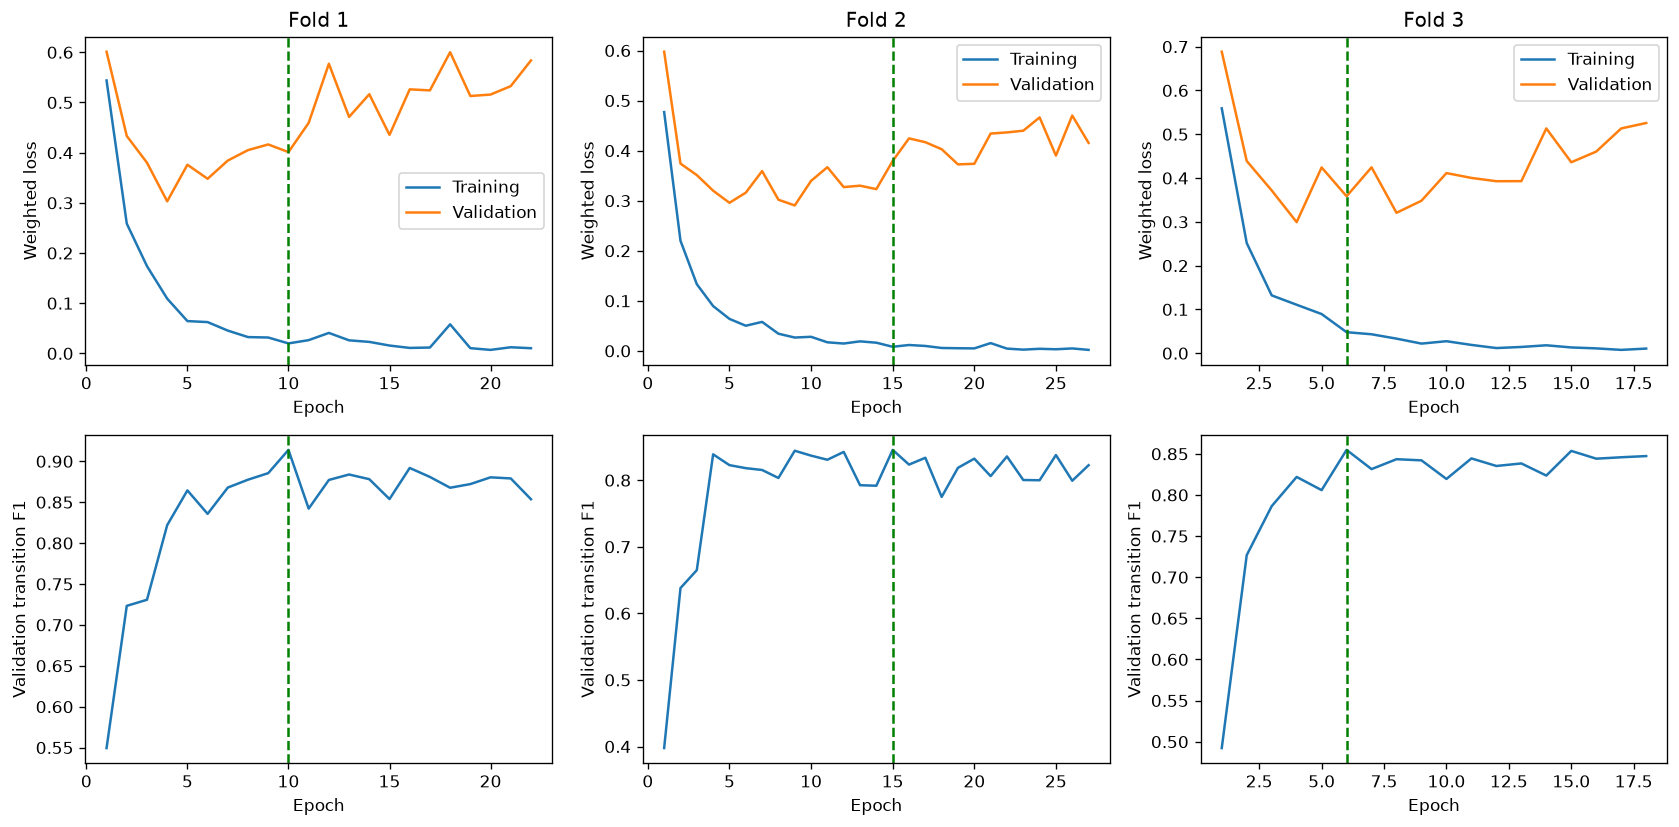

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for column, result in enumerate([r for r in chosen if r['split_seed'] == 42]):
    history = result['history']
    epochs = [row['epoch'] for row in history]
    axes[0, column].plot(epochs, [row['train_loss'] for row in history], label='Training')
    axes[0, column].plot(epochs, [row['validation_loss'] for row in history], label='Validation')
    axes[0, column].axvline(result['best_epoch'], color='green', linestyle='--')
    axes[0, column].set(title=f'Fold {column + 1}', xlabel='Epoch', ylabel='Weighted loss')
    axes[0, column].legend()
    axes[1, column].plot(epochs, [row['transition_f1'] for row in history])
    axes[1, column].axvline(result['best_epoch'], color='green', linestyle='--')
    axes[1, column].set(xlabel='Epoch', ylabel='Validation transition F1')
fig.tight_layout()
plt.show()


## 13. Check every transition, not just the average

These are per-class F1 means across the nine participant-validation folds,
comparing the old NN + memory with the chosen setting. They are not test
scores. Keeping this detail makes a gain in one transition and a loss in
another visible before final test evaluation.


In [13]:
old_f1 = np.mean([r['memory']['class_f1'] for r in reference], axis=0)
new_f1 = np.mean([r[best_method]['class_f1'] for r in chosen], axis=0)
print(f'{"Transition":22} {"Previous F1":>12} {"Selected F1":>12} {"Change":>9}')
for activity in range(6, 12):
    print(f'{names[activity]:22} {old_f1[activity]:12.4f} {new_f1[activity]:12.4f}'
          f' {new_f1[activity] - old_f1[activity]:+9.4f}')


Transition              Previous F1  Selected F1    Change
STAND_TO_SIT                 0.7908       0.8885   +0.0977
SIT_TO_STAND                 0.8768       0.9818   +0.1050
SIT_TO_LIE                   0.8905       0.9505   +0.0600
LIE_TO_SIT                   0.7027       0.8723   +0.1696
STAND_TO_LIE                 0.8340       0.8965   +0.0625
LIE_TO_STAND                 0.6061       0.8607   +0.2545


The selected setting is evaluated on test participants only in the main
notebook after selection is frozen. The project's test set has been viewed
before, so final test numbers remain developmental. No CSVs or model files
are written by this tuning notebook.
